In [19]:
import pandas as pd
import numpy as np

In [20]:
low_mass_central_df = pd.read_parquet ('../../data/low_mass_central_df_annuli_revised.parquet')

In [21]:
high_mass_central_df = pd.read_parquet ('../../data/high_mass_central_df_annuli_revised.parquet')

In [22]:
all_centrals_df = pd.concat([low_mass_central_df, high_mass_central_df], ignore_index=True)
print(f"Combined dataframe has {len(all_centrals_df)} rows.")

Combined dataframe has 48576 rows.


In [23]:
all_centrals_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,veldisp,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr
0,312415.0,0.071176,8.105450,-3.995854,7.655353,1,0.0,0.509563,0.001050,0,64.871277,0.295028,0.00000,9.881313e-324,980.83374,45.328607,0.155899,0.12591,9.881313e-324,180
1,312415.0,0.213527,8.175151,-3.359508,7.247262,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.00000,9.881313e-324,980.83374,45.328607,0.155899,0.12591,9.881313e-324,180
2,312415.0,0.355879,7.912692,-2.209567,6.888073,0,0.0,0.509563,0.001050,0,64.871277,0.295028,0.00000,9.881313e-324,980.83374,45.328607,0.155899,0.12591,9.881313e-324,180
3,312415.0,0.498230,7.599713,-4.369588,6.704756,1,0.0,0.509563,0.001050,0,64.871277,0.295028,0.00000,9.881313e-324,980.83374,45.328607,0.155899,0.12591,9.881313e-324,180
4,312415.0,0.640582,7.371823,-4.605686,6.710869,1,0.0,0.509563,0.001050,0,64.871277,0.295028,0.00000,9.881313e-324,980.83374,45.328607,0.155899,0.12591,9.881313e-324,180
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48571,594444.0,0.169860,9.321200,-2.636930,6.265163,1,0.0,2.942021,0.006637,0,89.968681,0.066943,20629.90625,0.000000e+00,19.27466,19.981537,-0.021362,0.07019,2.062991e+04,6053
48572,594444.0,0.509579,8.999712,-1.776677,6.709038,0,0.0,2.942021,0.006637,0,89.968681,0.066943,20629.90625,0.000000e+00,19.27466,19.981537,-0.021362,0.07019,2.062991e+04,6053
48573,594444.0,0.849298,8.734355,-3.316755,7.059817,1,0.0,2.942021,0.006637,0,89.968681,0.066943,20629.90625,0.000000e+00,19.27466,19.981537,-0.021362,0.07019,2.062991e+04,6053
48574,594444.0,1.189017,8.498129,-3.504491,6.857232,1,0.0,2.942021,0.006637,0,89.968681,0.066943,20629.90625,0.000000e+00,19.27466,19.981537,-0.021362,0.07019,2.062991e+04,6053


In [24]:
# # calculating star forming efficiency (SFE) and gas fraction 
# low_mass_satellite_df['SFE'] = 10**(low_mass_satellite_df['avg_SFR'] - low_mass_satellite_df['avg_gas_mass'])
# low_mass_satellite_df['f_gas'] = 10**(low_mass_satellite_df['avg_gas_mass'] - low_mass_satellite_df['avg_s_mass'])

In [25]:
# # remove the rows where the sfr_indicator is 0.0 -> implies artificially imposed minimum
# low_mass_satellite_df = low_mass_satellite_df[low_mass_satellite_df['sfr_indicator'] != 0.0]
# low_mass_satellite_df

In [26]:
# keep only star-forming regions (quenching vector value = 0)
all_centrals_df = all_centrals_df[all_centrals_df['quenching_vector'] == 0].reset_index(drop=True)
print(f"Star-forming dataframe has {len(all_centrals_df)} rows.")
all_centrals_df

Star-forming dataframe has 32953 rows.


,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,veldisp,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr
0,312415.0,0.213527,8.175151,-3.359508,7.247262,0,0.000000,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
1,312415.0,0.355879,7.912692,-2.209567,6.888073,0,0.000000,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
2,312415.0,0.925285,7.054781,-4.070769,6.963181,0,0.000000,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
3,312415.0,1.067636,6.900457,-3.289078,7.173378,0,0.000000,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
4,312415.0,1.209988,6.796739,-2.832557,7.367570,0,0.000000,0.509563,0.001050,0,64.871277,0.295028,0.000000,9.881313e-324,980.833740,45.328607,0.155899,0.125910,9.881313e-324,180
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32948,562410.0,1.119661,8.413935,-1.564219,7.630833,0,0.000000,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
32949,562410.0,1.439564,8.239394,-2.031924,7.606252,0,0.000000,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
32950,562410.0,1.759467,7.978919,-2.663112,7.356964,0,0.000000,2.275262,0.004635,0,82.065796,1.607175,2461.513184,1.389233e-316,34.545956,4.056387,-0.793238,0.072292,2.461513e+03,4058
32951,563241.0,0.172311,9.596712,-2.317702,7.677955,0,0.212526,2.357653,0.008387,0,82.442406,0.016811,553251.687500,0.000000e+00,38.519566,54.214864,0.083967,0.068477,5.532517e+05,4100


In [27]:
all_centrals_df.shape

(32953, 20)

In [28]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import RobustScaler

# 'BHMass', 'BHCum_QM', 'Mhalo', and 'overdens' are the features wer are testing
all_centrals_df = all_centrals_df.drop(columns=["class", "BH_cumQM", "BH_cumRM", "global_SFRs", "gas_mass","avg_gas_mass", "quenching_vector", "Bfld", "veldisp", "BH_AGN","bulge"])

<Axes: >

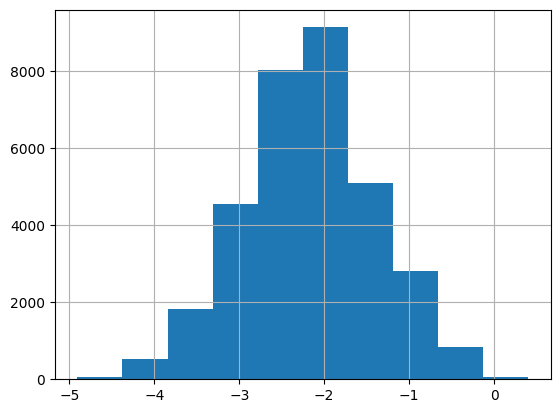

In [29]:
all_centrals_df['avg_SFR'].hist()

In [30]:
# this indicates that there are more instances of the delta rate on the left

In [31]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold

feature_importances_list = []
feature_names = None
test_mses = []
train_mses = []


for seed in range(10):
    # split halos (GrNr) into 50% training and 50% testing, so galaxies from the same halo never span train and test
    unique_halos = np.unique(all_centrals_df['GrNr'])
    train_galaxies, test_galaxies = train_test_split(unique_halos, test_size=0.5, random_state=seed)

    # assign galaxies based on halo split
    train_data = all_centrals_df[all_centrals_df['GrNr'].isin(train_galaxies)]
    test_data = all_centrals_df[all_centrals_df['GrNr'].isin(test_galaxies)]

    X_train, y_train = train_data.drop(columns=['avg_SFR', 'subID', 'GrNr']), train_data['avg_SFR']
    X_test, y_test = test_data.drop(columns=['avg_SFR', 'subID', 'GrNr']), test_data['avg_SFR']
    
    
    if feature_names is None:
        feature_names = X_train.columns.tolist()

    scaler = RobustScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    param_grid = {
    'n_estimators': [100,200, 300, 400, 500],  
    'max_depth': [50, 100, 150, 200, 250],  
    'min_samples_split': [50, 100, 150],  
    'min_samples_leaf': [300, 400, 500, 600],  
    'max_features': [None], 
    'bootstrap': [True],
    }
    rf_regressor = RandomForestRegressor(random_state=seed, n_jobs=-1)
    groups_train = train_data['GrNr']
    cv = GroupKFold(n_splits=5)

    random_search = RandomizedSearchCV(
    estimator=rf_regressor, 
    param_distributions=param_grid, 
    n_iter=10,
    cv=cv, 
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    random_state=seed,
    verbose=2)

    random_search.fit(X_train_scaled, y_train, groups=groups_train)

    best_rf_regressor = random_search.best_estimator_

    best_rf_regressor.fit(X_train_scaled, y_train)
    
    y_train_pred = best_rf_regressor.predict(X_train_scaled)
    y_test_pred = best_rf_regressor.predict(X_test_scaled)
    
    train_mse = mean_squared_error(y_train, y_train_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    
    train_mses.append(train_mse)
    test_mses.append(test_mse)
    
    feature_importances_list.append(best_rf_regressor.feature_importances_)
#     print(random_search.best_params_)
    print(f"Run {seed+1}: Train MSE = {train_mse:.4f}, Test MSE = {test_mse:.4f}")

print("\nAverage MSE over 10 runs:")
print(f"Train MSE: Mean = {np.mean(train_mses):.4f}, Std = {np.std(train_mses):.4f}")
print(f"Test MSE:  Mean = {np.mean(test_mses):.4f}, Std = {np.std(test_mses):.4f}")


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 1: Train MSE = 0.2722, Test MSE = 0.2885
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 2: Train MSE = 0.2654, Test MSE = 0.2874
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 3: Train MSE = 0.2698, Test MSE = 0.2810
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 4: Train MSE = 0.2743, Test MSE = 0.2772
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 5: Train MSE = 0.2649, Test MSE = 0.2890
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 6: Train MSE = 0.2728, Test MSE = 0.2843
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 7: Train MSE = 0.2705, Test MSE = 0.2816
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 8: Train MSE = 0.2731, Test MSE = 0.2841
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Run 9: Train MSE = 0.2704, Test MSE = 0.2793
Fitting 5 folds for each of 10 candidates, tot


=== Average Feature Importances ===
      Feature  Mean Importance   Std Dev
1  avg_s_mass         0.737359  0.011824
3      BHMass         0.222708  0.013931
2      s_mass         0.022538  0.014830
0   bin_radii         0.011787  0.001964
4       Mhalo         0.004451  0.004790
5    overdens         0.001157  0.001228


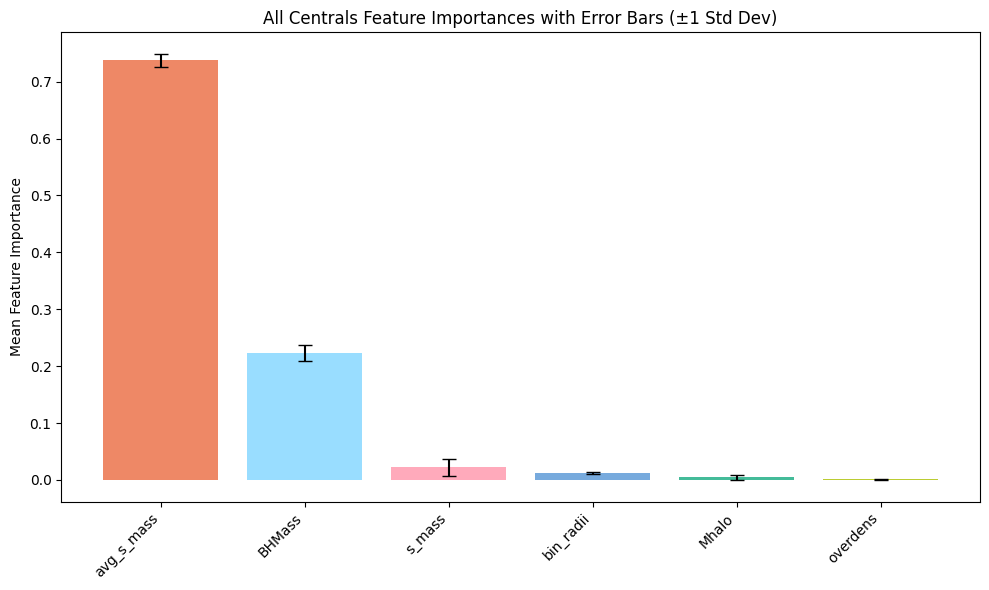

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
feature_colors = {
    'bin_radii': '#77AADD',
    'avg_s_mass': '#EE8866',
    's_mass': '#FFAABB',
    'BHMass': '#99DDFF',
    'Mhalo': '#44BB99',
    'overdens': '#BBCC33',
    'bulge': '#AAAA00',
    'BH_AGN': '#DDDDDD',
}

# importances + stds across 10 runs
importances_array = np.array(feature_importances_list)
importance_means = np.mean(importances_array, axis=0)
importance_stds = np.std(importances_array, axis=0)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Importance': importance_means,
    'Std Dev': importance_stds
}).sort_values(by='Mean Importance', ascending=False)

print("\n=== Average Feature Importances ===")
print(importance_df)

colors = [feature_colors[feat] for feat in importance_df['Feature']]
# Plot
plt.figure(figsize=(10, 6))
plt.bar(importance_df['Feature'], importance_df['Mean Importance'], yerr=importance_df['Std Dev'], capsize=5, color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Mean Feature Importance")
plt.title("All Centrals Feature Importances with Error Bars (±1 Std Dev)")
plt.tight_layout()
plt.show()

In [33]:
all_centrals_df.corr()

,subID,bin_radii,avg_s_mass,avg_SFR,s_mass,BHMass,Mhalo,overdens,GrNr
subID,1.000000,-0.012809,-0.296515,0.149123,-0.761148,-0.734478,-0.622858,-0.145762,0.774601
bin_radii,-0.012809,1.000000,-0.764428,-0.505080,-0.020475,-0.025588,-0.021604,0.002560,-0.020040
avg_s_mass,-0.296515,-0.764428,1.000000,0.570652,0.160817,0.153218,0.085471,0.041921,-0.342028
avg_SFR,0.149123,-0.505080,0.570652,1.000000,-0.175206,-0.173940,-0.151644,0.037902,-0.017403
s_mass,-0.761148,-0.020475,0.160817,-0.175206,1.000000,0.985867,0.916946,0.186934,-0.357099
BHMass,-0.734478,-0.025588,0.153218,-0.173940,0.985867,1.000000,0.902858,0.159274,-0.335495
Mhalo,-0.622858,-0.021604,0.085471,-0.151644,0.916946,0.902858,1.000000,0.292439,-0.243046
overdens,-0.145762,0.002560,0.041921,0.037902,0.186934,0.159274,0.292439,1.000000,-0.052605
GrNr,0.774601,-0.020040,-0.342028,-0.017403,-0.357099,-0.335495,-0.243046,-0.052605,1.000000


In [34]:
import os
# Define your directory and file name
directory = 'rf_regression_outputs'
filename = 'all_centrals_rf_reg_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
importance_df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

DataFrame saved to rf_regression_outputs\all_centrals_rf_reg_halosplit.csv


In [35]:
train_mean = round(np.mean(train_mses), 2)
test_mean = round(np.mean(test_mses), 2)

df = pd.DataFrame({
    'Train MSE': [train_mean],
    'Test MSE': [test_mean]
})

print(df)
import os
# Define your directory and file name
directory = 'rf_regression_outputs'
filename = 'all_centrals_rf_reg_mse_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

   Train MSE  Test MSE
0       0.27      0.28
DataFrame saved to rf_regression_outputs\all_centrals_rf_reg_mse_halosplit.csv


In [36]:
#compare MSE to variance of the target variable (avg_SFR)
mse_mean = np.mean(test_mses)
target_std = all_centrals_df['avg_SFR'].std()
target_var = all_centrals_df['avg_SFR'].var()
print(f"Mean Test MSE: {mse_mean:.4f}")
print(f"Standard Deviation of avg_SFR: {target_std:.4f}")
print(f"Variance of avg_SFR: {target_var:.4f}")

Mean Test MSE: 0.2832
Standard Deviation of avg_SFR: 0.7791
Variance of avg_SFR: 0.6070
